## Figure 1: schematic of the idealized mean flow and topography

Two-panel figure:
- **Top**: along-shelf velocity profile $U(y)$
- **Bottom**: cross-shelf depth profile $h(y)$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

### Grid

In [2]:
Lx = 1000e3   # m
Ly = 400e3    # m
dx = 1000     # m
dy = 1000     # m
nx = int(Lx / dx)
ny = int(Ly / dy)

xh = np.linspace(dx/2, Lx - dx/2, nx)
yh = np.linspace(dy/2, Ly - dy/2, ny)
xq = np.linspace(0, Lx, nx + 1)
Xq, Yh_u = np.meshgrid(xq, yh)

### Physical parameters

In [3]:
f    = -1e-5   # s^-1  (Coriolis)
g    = 9.81    # m s^-2
U    = 0.20    # m s^-1  (jet amplitude)
Ljet = 10e3   # m       (jet half-width)
Yj   = Ly / 2  # m       (jet centre)

slope_width_km = 50.0   # km  physical slope width
Ys = Ly / 2              # m   slope centre (200 km)

### Velocity field

In [4]:
yprime_u = (Yh_u - Yj) / Ljet
u_clean  = U * np.tanh(yprime_u)    # shape (ny, nx+1)
u_1d     = u_clean[:, nx // 2]      # 1-D slice at x = Lx/2

### Bathymetry

In [5]:
shallow_depth  = 100.0   # m  shelf depth
deep_depth     = 500.0   # m  basin depth
slope_width_km = 50.0    # km  physical slope width

# tanh bathymetry; 90% of the depth change occurs within slope_width_km
steepness = (slope_width_km * 1e3) / (2 * np.arctanh(0.9))
depth_profile_y = shallow_depth + (deep_depth - shallow_depth) * \
                  (np.tanh((yh - Ys) / steepness) + 1) / 2

yh_km = yh / 1e3
Yj_km = Yj / 1e3
Ys_km = Ys / 1e3
# slope extent used for shading and arrows
ss_km = (Ys - slope_width_km * 1e3 / 2) / 1e3
se_km = (Ys + slope_width_km * 1e3 / 2) / 1e3

### Plot

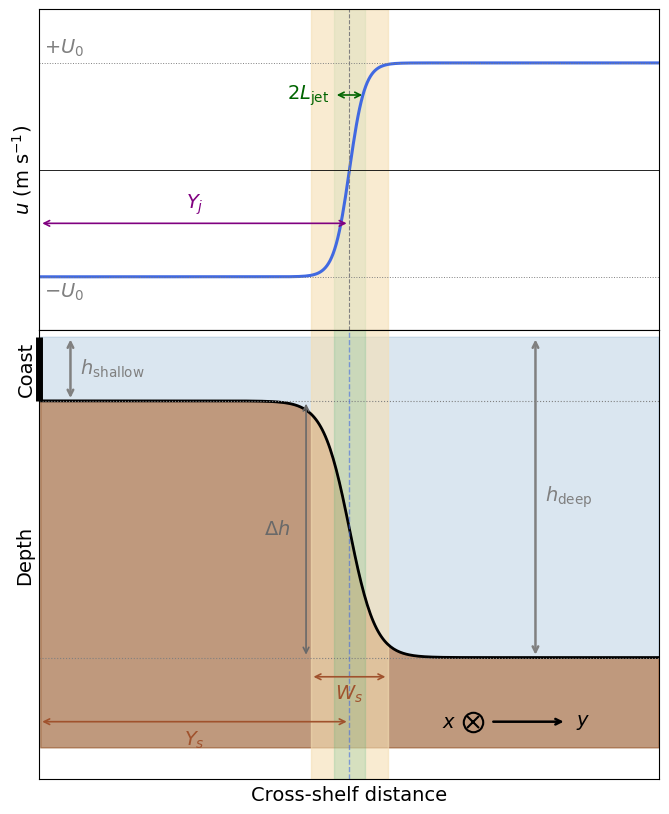

Saved: idealized_IC_diagram.png / .pdf


In [6]:
# Two rows, shared x-axis
fig = plt.figure(figsize=(8, 10))
gs  = gridspec.GridSpec(2, 1, figure=fig,
                         height_ratios=[1, 1.4],
                         hspace=0.0)
ax_u1d  = fig.add_subplot(gs[0])
ax_topo = fig.add_subplot(gs[1], sharex=ax_u1d)

# TOP PANEL — velocity profile u(y)

ax_u1d.axvspan(Yj_km - Ljet/1e3, Yj_km + Ljet/1e3, color='mediumseagreen', alpha=0.18)
ax_u1d.axvspan(ss_km, se_km, color='wheat', alpha=0.6)

ax_u1d.plot(yh_km, u_1d, 'royalblue', lw=2.2)
ax_u1d.axhline(0,      color='k',    lw=0.6)
ax_u1d.axvline(Yj_km,  color='gray', lw=0.8, ls='--')
ax_u1d.axhline( U,     color='gray', lw=0.7, ls=':')
ax_u1d.axhline(-U,     color='gray', lw=0.7, ls=':')
ax_u1d.text(3,  U + 0.008, r'$+U_0$', fontsize=14, color='gray', va='bottom')
ax_u1d.text(3, -U - 0.008, r'$-U_0$', fontsize=14, color='gray', va='top')

# 2 Ljet arrow
arrow_ljet_u = 0.14
ax_u1d.annotate('', xy=(Yj_km + Ljet/1e3, arrow_ljet_u),
                 xytext=(Yj_km - Ljet/1e3, arrow_ljet_u),
                 arrowprops=dict(arrowstyle='<->', color='darkgreen', lw=1.2))
ax_u1d.text(Yj_km - Ljet/1e3 - 3, arrow_ljet_u, r'$2L_\mathrm{jet}$',
             ha='right', va='center', fontsize=14, color='darkgreen')

# Yj arrow
arrow_Yj_u = -0.10
ax_u1d.annotate('', xy=(Yj_km, arrow_Yj_u),
                 xytext=(0, arrow_Yj_u),
                 arrowprops=dict(arrowstyle='<->', color='purple', lw=1.2))

ax_u1d.text(Yj_km / 2, arrow_Yj_u + 0.012, r'$Y_j$',
             ha='center', va='bottom', fontsize=14, color='purple')
ax_u1d.set_ylabel(r'$u$ (m s$^{-1}$)', fontsize=14)
ax_u1d.set_ylim(-0.30, 0.30)
ax_u1d.set_xlim(0, Ly / 1e3)
ax_u1d.grid(True, alpha=0.25)
plt.setp(ax_u1d.get_xticklabels(), visible=False)

# BOTTOM PANEL — bathymetric cross-section

ax_topo.fill_between(yh_km, 0, -depth_profile_y, color='steelblue', alpha=0.20)
ax_topo.fill_between(yh_km, -depth_profile_y, -640, color='saddlebrown', alpha=0.55)
ax_topo.plot(yh_km, -depth_profile_y, 'k', lw=2)

ax_topo.axvspan(ss_km, se_km, color='wheat', alpha=0.6)
ax_topo.axvspan(Yj_km - Ljet/1e3, Yj_km + Ljet/1e3, color='mediumseagreen', alpha=0.18)

# Δh arrow
ax_topo.annotate('', xy=(ss_km - 3, -shallow_depth),
                  xytext=(ss_km - 3, -deep_depth),
                  arrowprops=dict(arrowstyle='<->', color='dimgray', lw=1.2))
ax_topo.text(ss_km - 13, -(shallow_depth + deep_depth) / 2,
             r'$\Delta h$', ha='right', va='center', fontsize=14, color='dimgray')

# Ws arrow
ax_topo.annotate('', xy=(se_km, -530), xytext=(ss_km, -530),
                  arrowprops=dict(arrowstyle='<->', color='sienna', lw=1.2))
ax_topo.text(Ys_km, -540, r'$W_s$', ha='center', va='top', fontsize=14, color='sienna')

# Ys arrow
ax_topo.annotate('', xy=(Ys_km, -600), xytext=(0, -600),
                  arrowprops=dict(arrowstyle='<->', color='sienna', lw=1.2))
ax_topo.text(Ys_km / 2, -612, r'$Y_s$', ha='center', va='top', fontsize=14, color='sienna')

# h_shallow and h_deep arrows from the surface
x_hs = 20    # km
x_hd = 320   # km

ax_topo.annotate('', xy=(x_hs, -shallow_depth), xytext=(x_hs, 0),
                  arrowprops=dict(arrowstyle='<->', color='gray', lw=1.8))
ax_topo.text(x_hs + 6, -shallow_depth / 2, r'$h_\mathrm{shallow}$',
             ha='left', va='center', fontsize=14, color='gray')

ax_topo.annotate('', xy=(x_hd, -deep_depth), xytext=(x_hd, 0),
                  arrowprops=dict(arrowstyle='<->', color='gray', lw=1.8))
ax_topo.text(x_hd + 6, -deep_depth / 2, r'$h_\mathrm{deep}$',
             ha='left', va='center', fontsize=14, color='gray')

# Coastline at y = 0
ax_topo.plot([0, 0], [0, -shallow_depth], color='k', lw=5,
             solid_capstyle='butt', clip_on=False, zorder=7)
ax_topo.text(-2, -shallow_depth / 2, 'Coast', rotation=90,
             ha='right', va='center', fontsize=14, color='k', clip_on=False)

# Depth reference lines
ax_topo.axhline(-shallow_depth, color='gray', ls=':', lw=0.8)
ax_topo.axhline(-deep_depth,    color='gray', ls=':', lw=0.8)

# Jet centre
ax_topo.axvline(Yj_km, color='royalblue', lw=1, ls='--', alpha=0.6)

ax_topo.set_ylabel('Depth', fontsize=14)
ax_topo.set_xlabel('Cross-shelf distance', fontsize=14)
ax_topo.set_xlim(0, Ly / 1e3)
ax_u1d.set_xticks([])
ax_u1d.set_yticks([])
ax_topo.set_xticks([])
ax_topo.set_yticks([])
# Coordinate indicator: x along-shelf (into the page), y cross-shelf
cx, cy = 280, -600   # (km, m)

# x: into the page
ax_topo.plot([cx], [cy], marker='o', ms=14, mfc='none', mec='black', mew=1.5, zorder=6)
ax_topo.plot([cx], [cy], marker='x', ms=8, mec='black', mew=1.5, zorder=6)
ax_topo.text(cx - 11, cy, r'$x$', ha='right', va='center', fontsize=14, color='black')

# y: cross-shelf
ax_topo.annotate('', xy=(cx + 60, cy), xytext=(cx + 11, cy),
                  arrowprops=dict(arrowstyle='->', color='black', lw=1.8))
ax_topo.text(cx + 66, cy, r'$y$', ha='left', va='center', fontsize=14, color='black')

ax_topo.set_ylim(-690, 10)
plt.savefig('idealized_IC_diagram.png', bbox_inches='tight', dpi=180)
plt.savefig('idealized_IC_diagram.pdf', bbox_inches='tight')
plt.show()
print('Saved: idealized_IC_diagram.png / .pdf')